In [9]:
import pandas as pd

In [12]:
from src.load_data import load_data

In [15]:
df = load_data()

In [16]:
df.sample(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
12902,60,retired,divorced,tertiary,no,468,no,no,cellular,7,jul,108,2,-1,0,unknown,no
6169,40,blue-collar,married,primary,no,-335,yes,no,unknown,27,may,260,1,-1,0,unknown,no
24810,51,admin.,divorced,secondary,no,390,no,no,telephone,18,nov,368,1,-1,0,unknown,no
7299,50,management,married,unknown,no,914,yes,no,unknown,29,may,359,3,-1,0,unknown,no
7445,42,technician,married,secondary,no,2,no,no,unknown,29,may,249,2,-1,0,unknown,no
44783,41,admin.,married,secondary,no,3138,no,no,cellular,14,sep,409,1,398,1,failure,yes
18440,58,housemaid,married,tertiary,no,2858,no,no,cellular,31,jul,56,6,-1,0,unknown,no
21872,56,admin.,married,secondary,no,374,no,no,cellular,20,aug,193,4,-1,0,unknown,no
39411,36,management,married,tertiary,no,332,yes,no,cellular,22,may,566,7,-1,0,unknown,no
838,35,blue-collar,single,unknown,yes,-532,yes,no,unknown,7,may,149,1,-1,0,unknown,no


In [17]:
df.isnull().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

In [18]:
df["job"] = df["job"].fillna("Unkown")

In [19]:
df["contact"] = df["contact"].fillna("Unknown")

In [20]:
df["poutcome"] = df["poutcome"].fillna("Unknown")

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.dtypes

age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [24]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

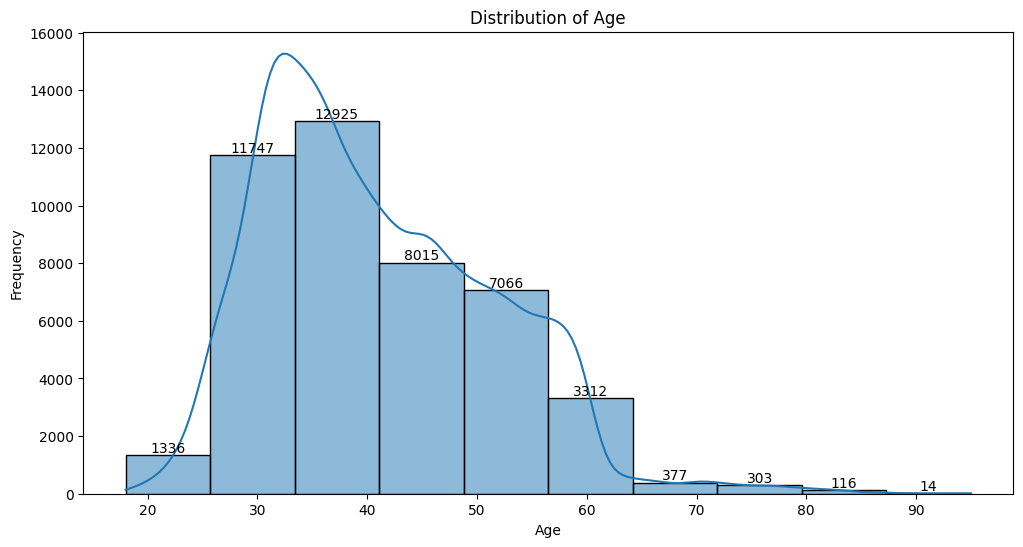

In [26]:
plt.figure(figsize=(12, 6))

ax = sns.histplot(data=df, x='age', bins=10, kde=True)
for containers in ax.containers:
    ax.bar_label(containers)

plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

C:\Users\deniz\AppData\Local\Temp\ipykernel_17464\3172392673.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='y', palette='viridis')


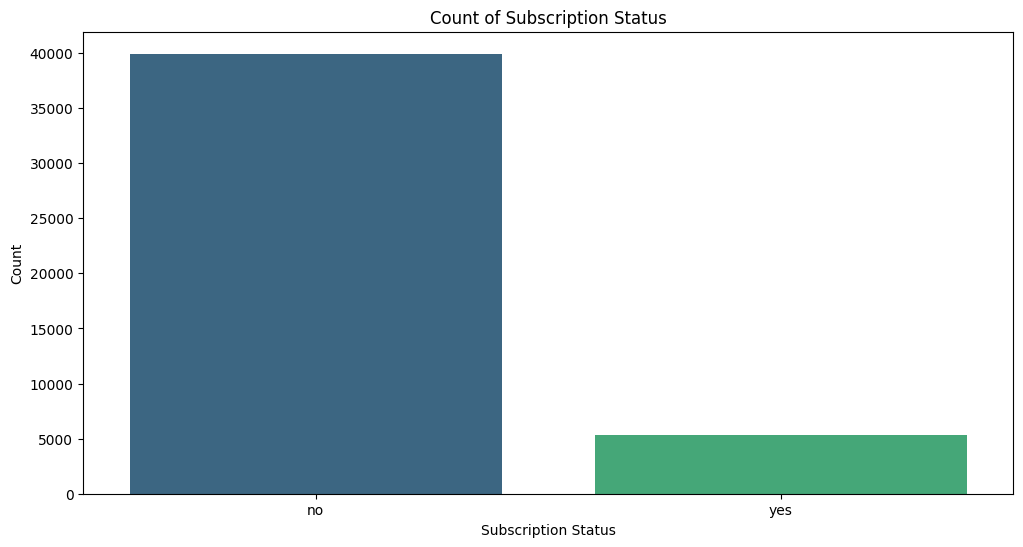

In [27]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, x='y', palette='viridis')
plt.title('Count of Subscription Status')
plt.xlabel('Subscription Status')
plt.ylabel('Count')
plt.show()

In [28]:
df['age_group'] = pd.cut(df['age'], bins=range(10,101,10))

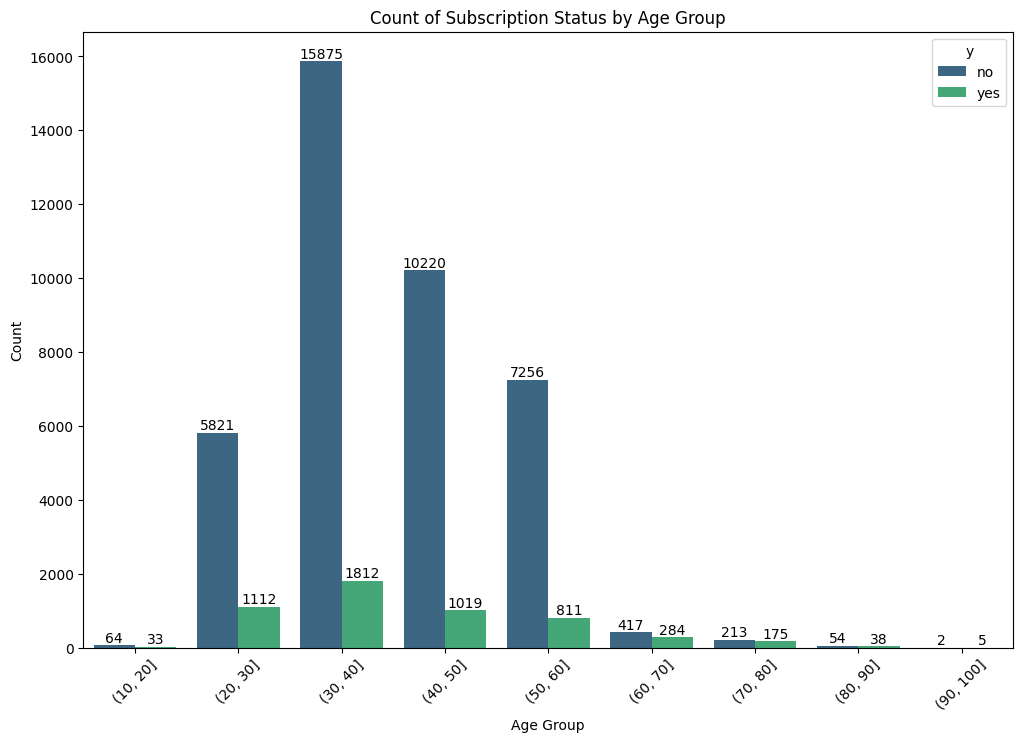

In [29]:
plt.figure(figsize=(12, 8))
ax = sns.countplot(data=df, x='age_group', hue='y', palette='viridis')
for containers in ax.containers:
    ax.bar_label(containers)
plt.xticks(rotation=45)
plt.title('Count of Subscription Status by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.show()

In [30]:
pd.crosstab(df['age_group'], df['y'], normalize='index') * 100

y,no,yes
age_group,,
"(10, 20]",65.979381,34.020619
"(20, 30]",83.960767,16.039233
"(30, 40]",89.755187,10.244813
"(40, 50]",90.933357,9.066643
"(50, 60]",89.946696,10.053304
"(60, 70]",59.486448,40.513552
"(70, 80]",54.896907,45.103093
"(80, 90]",58.695652,41.304348
"(90, 100]",28.571429,71.428571


Text(0, 0.5, 'Count')

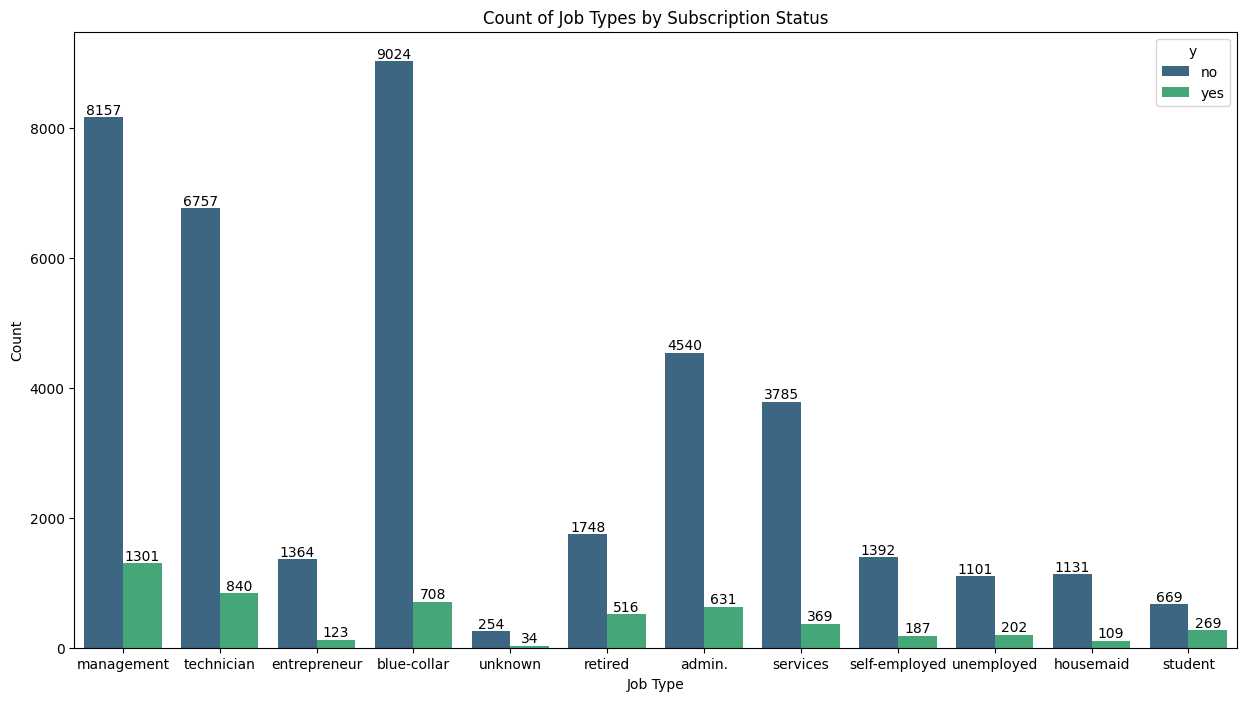

In [31]:
plt.figure(figsize=(15, 8))

ax = sns.countplot(data=df, x='job', hue='y', palette='viridis')
for containers in ax.containers:
    ax.bar_label(containers)
plt.title('Count of Job Types by Subscription Status')
plt.xlabel('Job Type')
plt.ylabel('Count')

In [32]:
pd.crosstab(df['job'], df['y'],  normalize='index') * 100

y,no,yes
job,,
admin.,87.797331,12.202669
blue-collar,92.725031,7.274969
entrepreneur,91.728312,8.271688
housemaid,91.209677,8.790323
management,86.244449,13.755551
retired,77.208481,22.791519
self-employed,88.157061,11.842939
services,91.116996,8.883004
student,71.321962,28.678038


In [33]:
pd.crosstab(df['marital'], df['y'], normalize='index') * 100

y,no,yes
marital,,
divorced,88.054542,11.945458
married,89.876534,10.123466
single,85.050821,14.949179


In [34]:
df['education'].value_counts()

education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

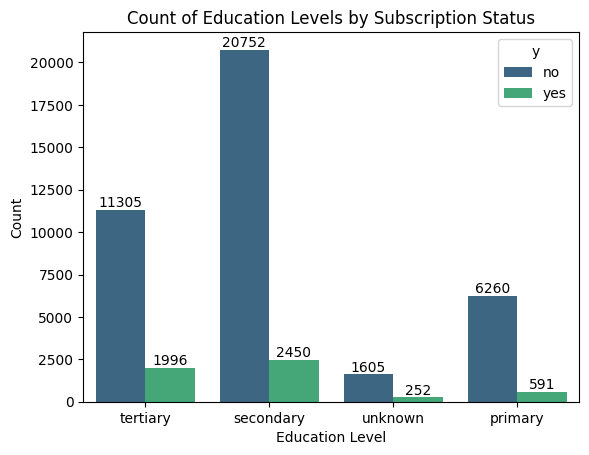

In [35]:
ax = sns.countplot(data=df, x='education', hue='y', palette='viridis')
for containers in ax.containers:
    ax.bar_label(containers)
plt.title('Count of Education Levels by Subscription Status')
plt.xlabel('Education Level')
plt.ylabel('Count')
plt.show()

In [36]:
pd.crosstab(df['education'], df['y'], normalize = 'index') * 100

y,no,yes
education,,
primary,91.373522,8.626478
secondary,89.440565,10.559435
tertiary,84.993610,15.006390
unknown,86.429725,13.570275


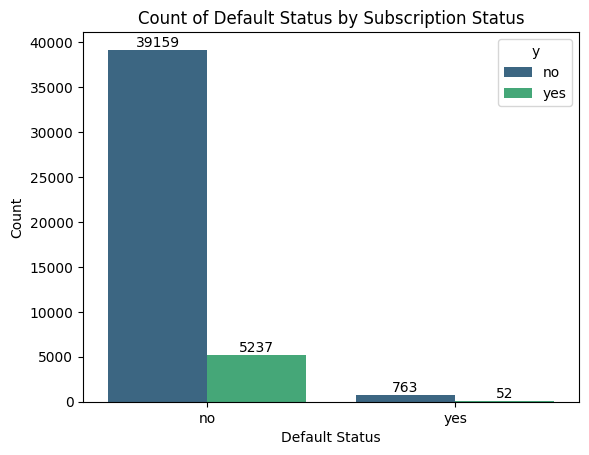

In [37]:
plt.Figure(figsize=(12, 6))

ax = sns.countplot(data=df, x='default', hue='y', palette='viridis')
for containers in ax.containers:
    ax.bar_label(containers)
plt.title('Count of Default Status by Subscription Status')
plt.xlabel('Default Status')
plt.ylabel('Count')
plt.show()

In [38]:
pd.crosstab(df['default'], df['y'], normalize='index') * 100

y,no,yes
default,,
no,88.203892,11.796108
yes,93.619632,6.380368


C:\Users\deniz\AppData\Local\Temp\ipykernel_17464\1848851072.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='y', y='balance', palette='viridis')


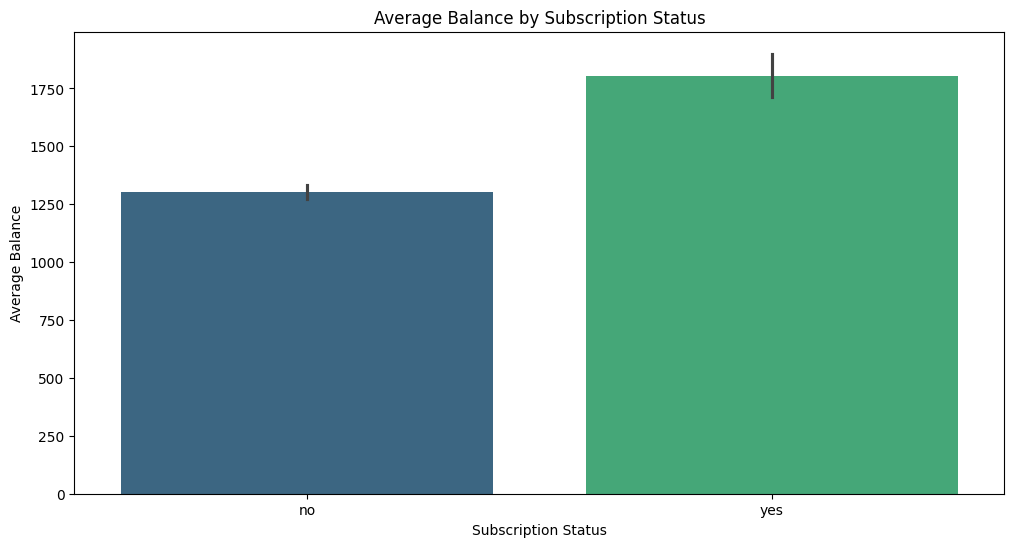

In [39]:
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='y', y='balance', palette='viridis')
plt.title('Average Balance by Subscription Status')
plt.xlabel('Subscription Status')
plt.ylabel('Average Balance')
plt.show()

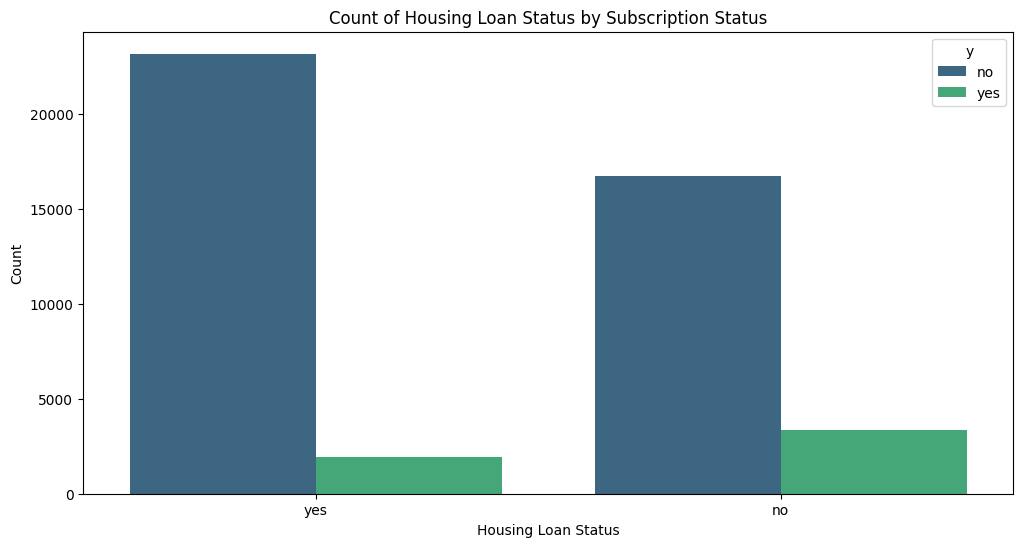

In [40]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='housing',hue='y', palette='viridis')
plt.title('Count of Housing Loan Status by Subscription Status')
plt.xlabel('Housing Loan Status')
plt.ylabel('Count')
plt.show()

In [41]:
pd.crosstab(df['housing'], df['y'], normalize='index') * 100

y,no,yes
housing,,
no,83.297645,16.702355
yes,92.300040,7.699960


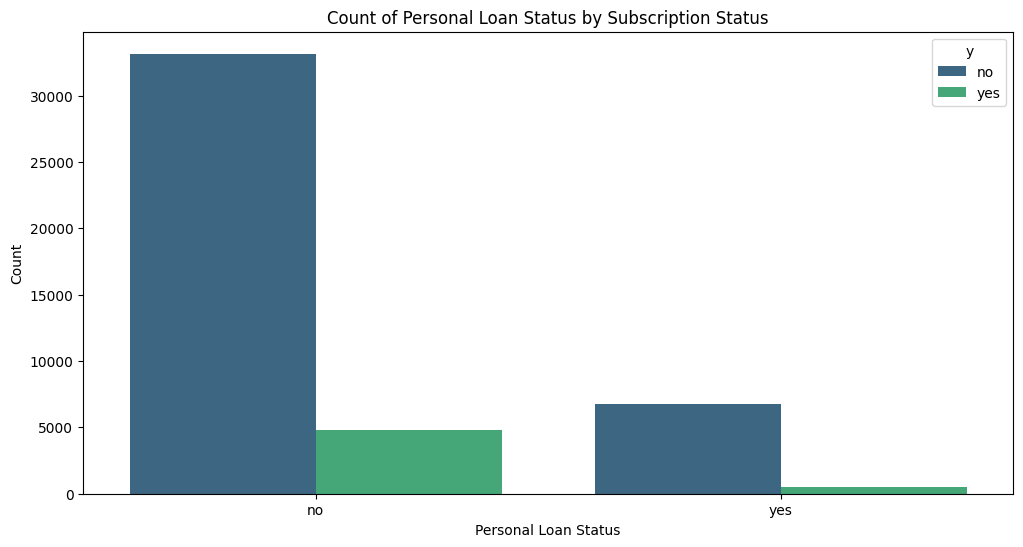

In [42]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='loan', hue='y', palette='viridis')
plt.title('Count of Personal Loan Status by Subscription Status')
plt.xlabel('Personal Loan Status')
plt.ylabel('Count')
plt.show()

In [43]:
pd.crosstab(df['housing'], df['y'], normalize='index') * 100

y,no,yes
housing,,
no,83.297645,16.702355
yes,92.300040,7.699960


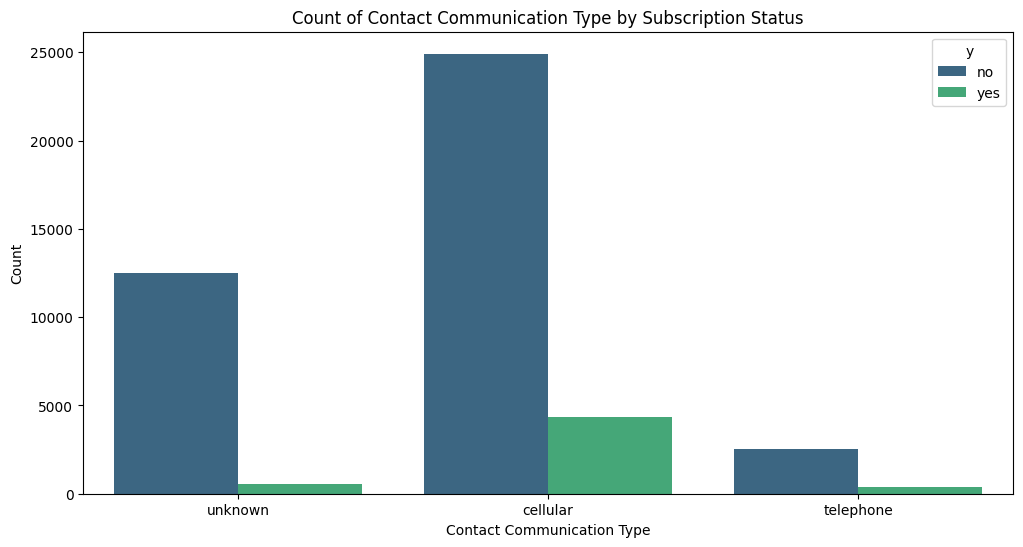

In [44]:
plt.figure(figsize=(12, 6))
sns.countplot(data=df, x='contact', hue='y', palette='viridis')
plt.title('Count of Contact Communication Type by Subscription Status')
plt.xlabel('Contact Communication Type')
plt.ylabel('Count')
plt.show()

In [45]:
pd.crosstab(df['contact'], df['y'], normalize='index') * 100

y,no,yes
contact,,
cellular,85.081100,14.918900
telephone,86.579491,13.420509
unknown,95.929339,4.070661


In [46]:
df['duration'].describe()

count    45211.000000
mean       258.163080
std        257.527812
min          0.000000
25%        103.000000
50%        180.000000
75%        319.000000
max       4918.000000
Name: duration, dtype: float64

(0.0, 400.0)

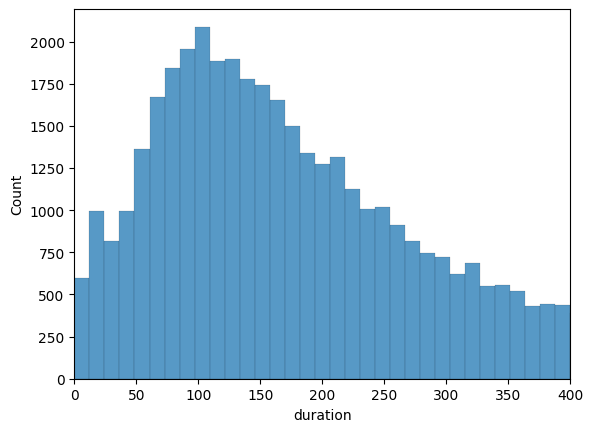

In [47]:
sns.histplot(data=df, x='duration')
plt.xlim(0, 400)

C:\Users\deniz\AppData\Local\Temp\ipykernel_17464\1332077231.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='y', y='duration', palette='viridis')


Text(0.5, 0, 'Subscription Status')

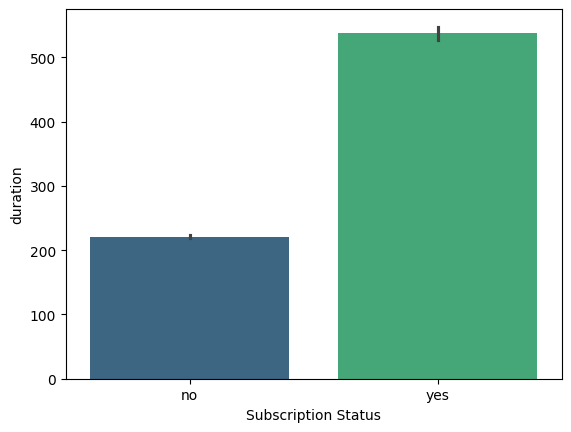

In [48]:
sns.barplot(data=df, x='y', y='duration', palette='viridis')
plt.xlabel('Subscription Status')

C:\Users\deniz\AppData\Local\Temp\ipykernel_17464\98913126.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='y', y='duration', palette='viridis')


(0.0, 2000.0)

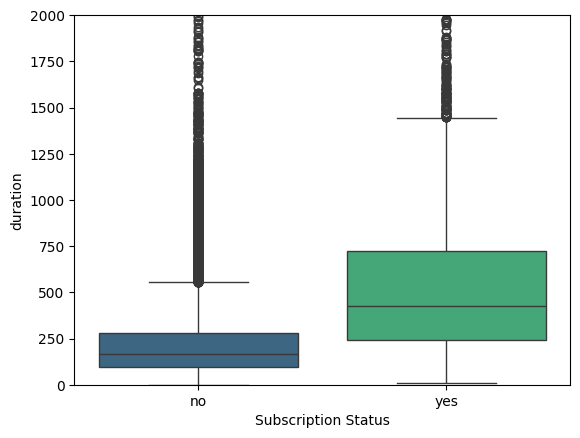

In [49]:
sns.boxplot(data=df, x='y', y='duration', palette='viridis')
plt.xlabel('Subscription Status')
plt.ylim(0, 2000)

In [50]:
print("Skewness of duration:", df['duration'].skew())

Skewness of duration: 3.144318099423455


In [51]:
print("Kurtosis of duration:", df['duration'].kurtosis())

Kurtosis of duration: 18.1539152690197


In [52]:
df['campaign'].describe()

count    45211.000000
mean         2.763841
std          3.098021
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         63.000000
Name: campaign, dtype: float64

([<matplotlib.axis.XTick at 0x16e49ee9450>,
 [Text(0, 0, '1'),
  Text(1, 0, '2'),
  Text(2, 0, '3'),
  Text(3, 0, '4'),
  Text(4, 0, '5'),
  Text(5, 0, '6'),
  Text(6, 0, '7'),
  Text(7, 0, '8'),
  Text(8, 0, '9'),
  Text(9, 0, '10'),
  Text(10, 0, '11')])

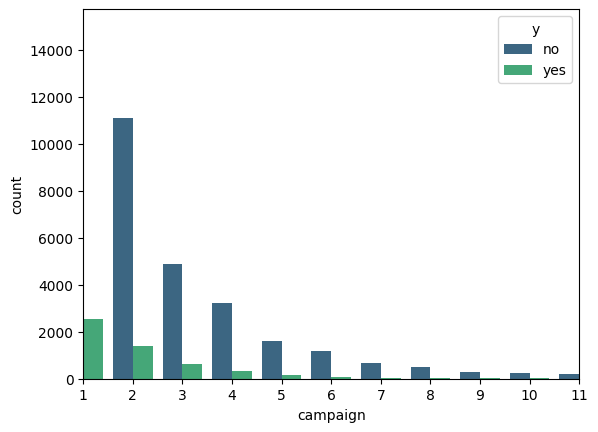

In [53]:
sns.countplot(data=df, x='campaign', hue='y', palette='viridis')
plt.xlim(0, 10)
plt.xticks(range(0, 11))

In [54]:
df['pdays'].describe()

count    45211.000000
mean        40.197828
std        100.128746
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         -1.000000
max        871.000000
Name: pdays, dtype: float64

Text(0.5, 0, 'Number of Days Since Last Contact')

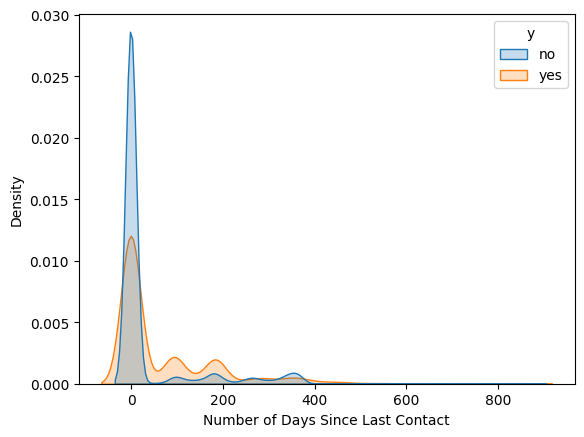

In [55]:
sns.kdeplot(data=df, x='pdays', hue='y', fill=True, common_norm=False)
plt.xlabel('Number of Days Since Last Contact')

In [56]:
df['previous'].describe()

count    45211.000000
mean         0.580323
std          2.303441
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        275.000000
Name: previous, dtype: float64

In [57]:
df['poutcome'].value_counts()

poutcome
unknown    36959
failure     4901
other       1840
success     1511
Name: count, dtype: int64

Text(0.5, 0, 'Previous Campaign Outcome')

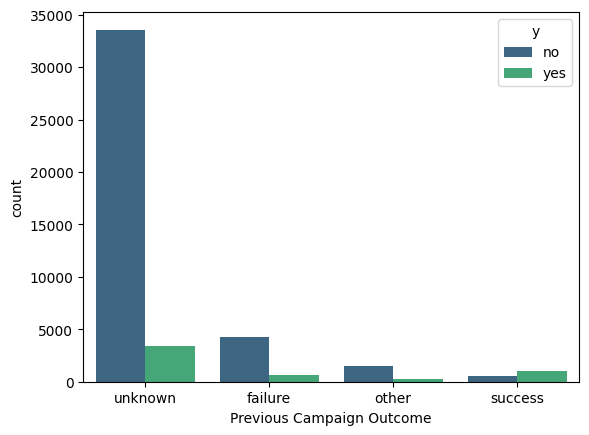

In [58]:
sns.countplot(data=df, x='poutcome', hue='y', palette='viridis')
plt.xlabel('Previous Campaign Outcome')

In [59]:
pd.crosstab(df['poutcome'], df['y'], normalize='index') * 100

y,no,yes
poutcome,,
failure,87.390329,12.609671
other,83.315217,16.684783
success,35.274653,64.725347
unknown,90.838497,9.161503


# Feature Engineering

In [60]:
df['age'].describe()

count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64

In [61]:
df['age_group'] = pd.cut(
    df['age'],
    bins=[0, 30, 50, 70, 100],
    labels=['18-30', '30-50', '50-70', '70+']
    )

In [62]:
df['balance'].describe()

count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64

In [63]:
df['balance_group'] = pd.cut(
    df['balance'],
    bins=[-float('inf'), 0, 1500, 20000, +float('inf')],
    labels=['Negative', 'Low', 'Medium', 'High']
)

In [64]:
df['previous_contact'] = (df['previous'] != -1).astype(int)

In [65]:
df['duration'].describe()

count    45211.000000
mean       258.163080
std        257.527812
min          0.000000
25%        103.000000
50%        180.000000
75%        319.000000
max       4918.000000
Name: duration, dtype: float64

In [66]:
df['duration_group'] = pd.cut(
    df['duration'],
    bins=[-1, 60, 180, 300, float('inf')],
    labels=['Very Short', 'Short', 'Medium', 'Long']
)